# Test neighborhood-level approach:

Note that the method below uses distances in latent space and so is not graph-based anymore

## Prep:

In [1]:
!pip install nb_black

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
     |████████████████████████████████| 1.7 MB 3.3 MB/s eta 0:00:01
  ERROR: Command errored out with exit status 1:
   command: /usr/bin/python -u -c 'import io, os, sys, setuptools, tokenize; sys.argv[0] = '"'"'/tmp/pip-install-5vqzncw_/nb-black_8440507e07a24744a99938e72d0ff0be/setup.py'"'"'; __file__='"'"'/tmp/pip-install-5vqzncw_/nb-black_8440507e07a24744a99938e72d0ff0be/setup.py'"'"';f = getattr(tokenize, '"'"'open'"'"', open)(__file__) if os.path.exists(__file__) else io.StringIO('"'"'from setuptools import setup; setup()'"'"');code = f.read().replace('"'"'\r\n'"'"', '"'"'\n'"'"');f.close();exec(compile(code, __file__, '"'"'exec'"'"'))' bdist_wheel -d /tmp/pip-wheel-au6h24v2
       cwd: /tmp/pip-install-5vqzncw_/nb-black_8440507e07a24744a99938e72d0ff0be/
  Complete output (76 lines):
  running bdist_wheel
  running build
  running build_py
  creating build
  creating build/lib
  copying nb_black.py -> build/

Failed to build nb-black
    Running setup.py install for nb-black ... done
  DEPRECATION: nb-black was installed using the legacy 'setup.py install' method, because a wheel could not be built for it. A possible replacement is to fix the wheel build issue reported above. You can find discussion regarding this at https://github.com/pypa/pip/issues/8368.
You should consider upgrading via the '/usr/bin/python -m pip install --upgrade pip' command.


In [2]:
!pip install scanpy

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
     |████████████████████████████████| 2.0 MB 3.1 MB/s eta 0:00:01     |████████▏                       | 522 kB 3.1 MB/s eta 0:00:01
     |████████████████████████████████| 4.8 MB 33.1 MB/s eta 0:00:01
     |████████████████████████████████| 233 kB 41.1 MB/s eta 0:00:01
     |████████████████████████████████| 104 kB 49.4 MB/s eta 0:00:01
     |████████████████████████████████| 88 kB 51.4 MB/s eta 0:00:01
     |████████████████████████████████| 10.1 MB 60.0 MB/s eta 0:00:01
     |████████████████████████████████| 1.1 MB 41.1 MB/s eta 0:00:01
     |████████████████████████████████| 75 kB 34.6 MB/s eta 0:00:01
  Created wheel for umap-learn: filename=umap_learn-0.5.3-py3-none-any.whl size=82830 sha256=8c067b41cb0bb227a7a7b4fead78464f8905c9161387a13e04eb7b18ac0b658e
  Stored in directory: /tmp/pip-ephem-wheel-cache-o8c5b4dc/wheels/a0/e8/c6/a37ea663620bd5200ea1ba0907ab3c217042c1d035ef606acc
  Created wheel for pynnde

load modules:

In [3]:
%load_ext nb_black

<IPython.core.display.Javascript object>

In [4]:
import numpy as np
import scanpy as sc
import pandas as pd
import random
import os
from os.path import abspath
import matplotlib.pyplot as plt
import seaborn as sns
import scipy

<IPython.core.display.Javascript object>

set parameters and paths:

In [5]:
plt.rcParams["figure.figsize"] = [15, 8]

<IPython.core.display.Javascript object>

In [6]:
dir_res = abspath(
    os.path.join(os.getcwd(), os.pardir, "Results", "Neighborhood_based_HLCA")
)

path_hlca_ext = abspath(
    os.path.join(os.getcwd(), os.pardir, "Data", "HLCA_full_tranf.h5ad")
)

<IPython.core.display.Javascript object>

In [7]:
Sheppard_healthy_unfiltered = f"{dir_res}/Sheppard_2020_Fibroblasts_Healthy/No_filter/"
Sheppard_healthy_filtered = f"{dir_res}/Sheppard_2020_Fibroblasts_Healthy/All_filter/"
Sheppard_healthy_props = (
    f"{dir_res}/Sheppard_2020_Fibroblasts_Healthy/proportion_tryout/"
)

Sheppard_IPF_unfiltered = f"{dir_res}/Sheppard_2020_Fibroblasts_IPF/No_filter/"
Sheppard_IPF_filtered = f"{dir_res}/Sheppard_2020_Fibroblasts_IPF/All_filter/"
# whole query+reference
Sheppard_healthy = f"{dir_res}/Sheppard_2020_Healthy/"
Sheppard_IPF = f"{dir_res}/Sheppard_2020_IPF/"
Sheppard_ScILD = f"{dir_res}/Sheppard_2020_ScILD/"
# Schiller 2020
Schiller_ELF = f"{dir_res}/Schiller_2020_Endstage_Lung_Fibrosis/"
Schiller_healthy = f"{dir_res}/Schiller_2020_Healthy/"
# Single Nucleus
Duong = f"{dir_res}/Duong_LungMAP/"
# Kaminski_2020
Kaminski_healthy = f"{dir_res}/Kaminski_2020_Healthy/"
Kaminski_IPF = f"{dir_res}/Kaminski_2020_IPF/"
Kaminski_COPD = f"{dir_res}/Kaminski_2020_COPD/"
# Meyer_2021
Meyer_3_prime = f"{dir_res}/Meyer_3_prime/"
Meyer_5_prime = f"{dir_res}/Meyer_5_prime/"
# Tata
Tata = f"{dir_res}/Tata/"

<IPython.core.display.Javascript object>

helperfunctions:

In [8]:
def load_stats(
    path,
    k_list=[50, 500, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000],
    prop=500,
    runs=20,
):
    list_results = []
    for k in k_list:
        n_list = []
        frac_list = []
        for i in range(0, runs):
            try:
                stats = pd.read_csv(f"{path}pvalues_{k}_{prop}_{i}.csv").dropna()
            except:
                continue
            if len(stats) < 1:
                continue
            n_significant = len(stats[stats.pvalue_corr < 0.05])
            n_list.append(n_significant)
            frac_list.append(n_significant / len(stats))
        if len(n_list) < 1:
            continue
        list_results.append(
            (k, np.mean(n_list), np.std(n_list), np.mean(frac_list), np.std(frac_list))
        )

    return pd.DataFrame(
        data=list_results,
        columns=["k", "n_significant", "std_significant", "fraction", "std_fraction"],
    )

<IPython.core.display.Javascript object>

In [9]:
def load_stats_prop(
    path,
    k_list=[50, 500, 1000, 5000],
    prop_list=[10, 50, 100, 200, 500, 700, 1000, 1500, 2000],
    runs=10,
):
    list_results = []
    for k in k_list:
        n_list = []
        frac_list = []
        for p in prop_list:
            for i in range(0, runs):
                stats = pd.read_csv(f"{path}pvalues_{k}_{p}_{i}.csv").dropna()
                if len(stats) < 1:
                    continue
                n_significant = len(stats[stats.pvalue_corr < 0.05])
                n_list.append(n_significant)
                frac_list.append(n_significant / len(stats))
            if len(n_list) < 1:
                continue
            list_results.append(
                (
                    k,
                    p,
                    np.mean(n_list),
                    np.std(n_list),
                    np.mean(frac_list),
                    np.std(frac_list),
                )
            )

    return pd.DataFrame(
        data=list_results,
        columns=[
            "k",
            "prop",
            "n_significant",
            "std_significant",
            "fraction",
            "std_fraction",
        ],
    )

<IPython.core.display.Javascript object>

In [10]:
def load_pvalues(path, k, p, i):
    try:
        return pd.read_csv(f"{path}pvalues_{k}_{p}_{i}.csv").dropna()
    except:
        print("No such data")
        return None

<IPython.core.display.Javascript object>

### Comparison of Sheppard_2020 Healthy Fibroblasts to IPF Fibroblasts in two modes: filtered and unfiltered

#### Mode comparison


**filtered**: 
1. neighborhoods with less than three samples are excluded from calculation\
2. samples with less than 5 cells in a neighborhood are ignored\
**unfiltered**:\
only neighborhoods with either no query or no reference samples are ignored\

We want to see whether filtering makes a significant difference/ we filter out too much and results are unexpected.

#### Comparison of Healthy and IPF

As fibroblasts are shown to be severly affected by IPF we expect to see a higher fraction of significant neighborhoods in IPF fibroblasts than in healthy fibroblasts. We expect that because in a scenario of mapping disease+healthy on a fully healthy reference we expect healthy query to be mixing with healthy reference. We expect the disease query to mix less, as disease samples should be more similar to other disease samples (of the same disease) than to the healthy reference.

parameters:
- proportion of cells samples: 1/500
- runs for standard deviation: 20

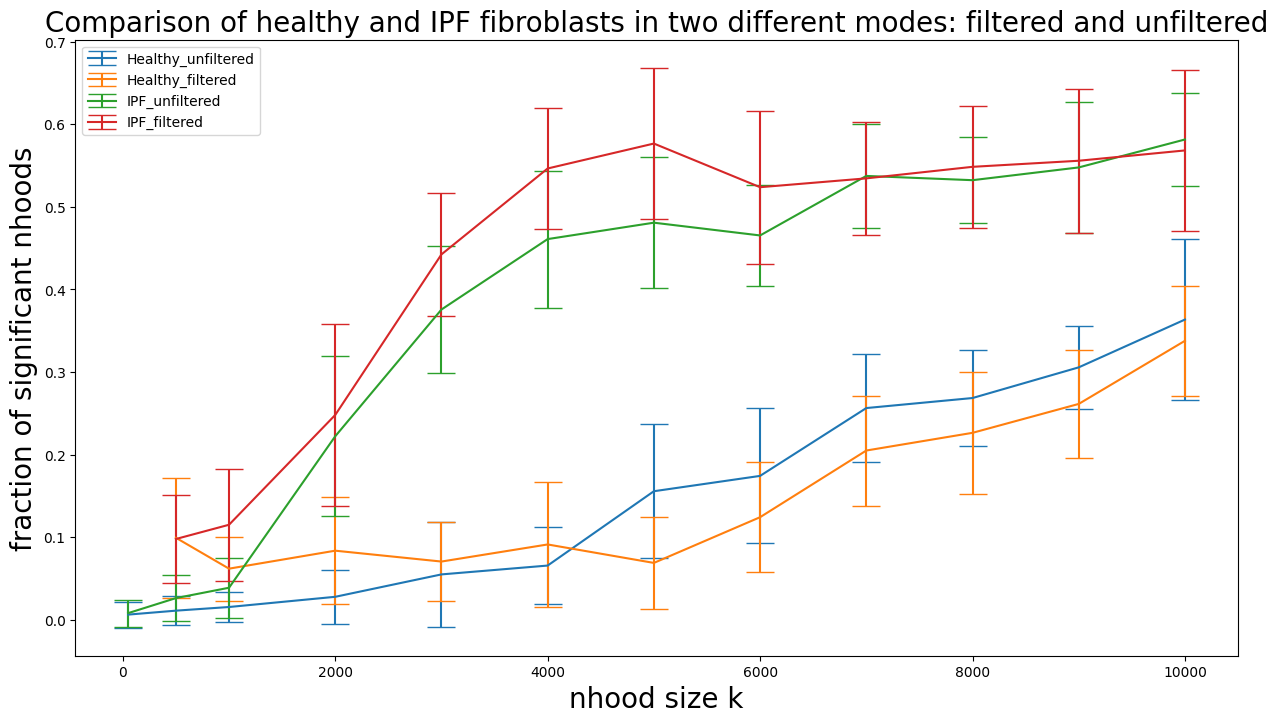

<IPython.core.display.Javascript object>

In [11]:
for name, path in [
    ("Healthy_unfiltered", Sheppard_healthy_unfiltered),
    ("Healthy_filtered", Sheppard_healthy_filtered),
    ("IPF_unfiltered", Sheppard_IPF_unfiltered),
    ("IPF_filtered", Sheppard_IPF_filtered),
]:
    stats = load_stats(path)
    plt.errorbar(
        x=stats.k, y=stats.fraction, yerr=stats.std_fraction, label=name, capsize=10
    )
plt.title(
    "Comparison of healthy and IPF fibroblasts in two different modes: filtered and unfiltered",
    fontsize=20,
)
plt.ylabel("fraction of significant nhoods", fontsize=20)
plt.xlabel("nhood size k", fontsize=20)
plt.legend()

The two modes don't seem to make a significant difference, which favors the filtered version to reduce computational burden.


The difference between healthy and disease is significant from $k \approx 3000$ but the significance reduces with higher $k$.

### Comparison of different fractions of sampled center cells

Here we compare fractions of sampled center cell. We expect that more sampled center cells don't produce more significant hits, as the p-values are multiple testing corrected with the number of center cells.

parameters:
- runs for standard deviation: 10

In [12]:
stats_prop = load_stats_prop(Sheppard_healthy_props)

<IPython.core.display.Javascript object>

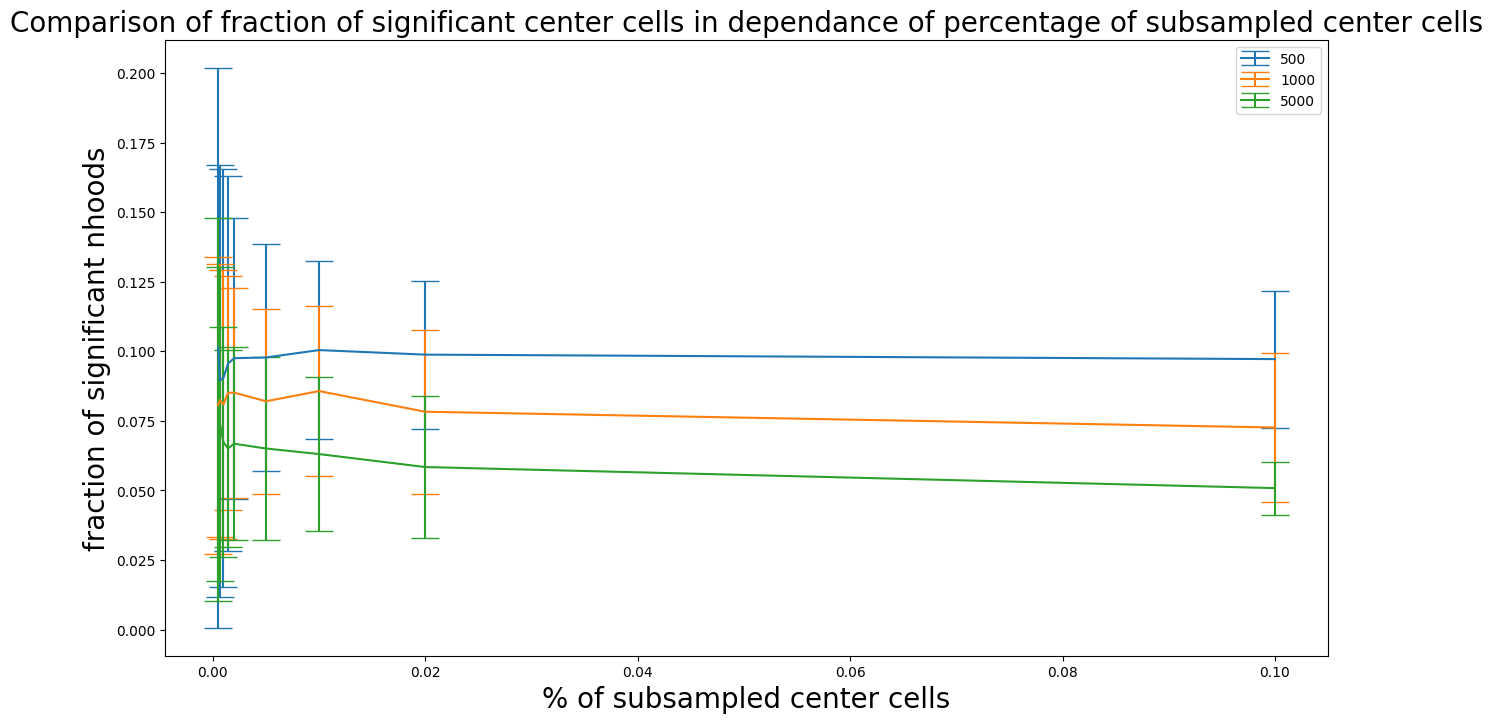

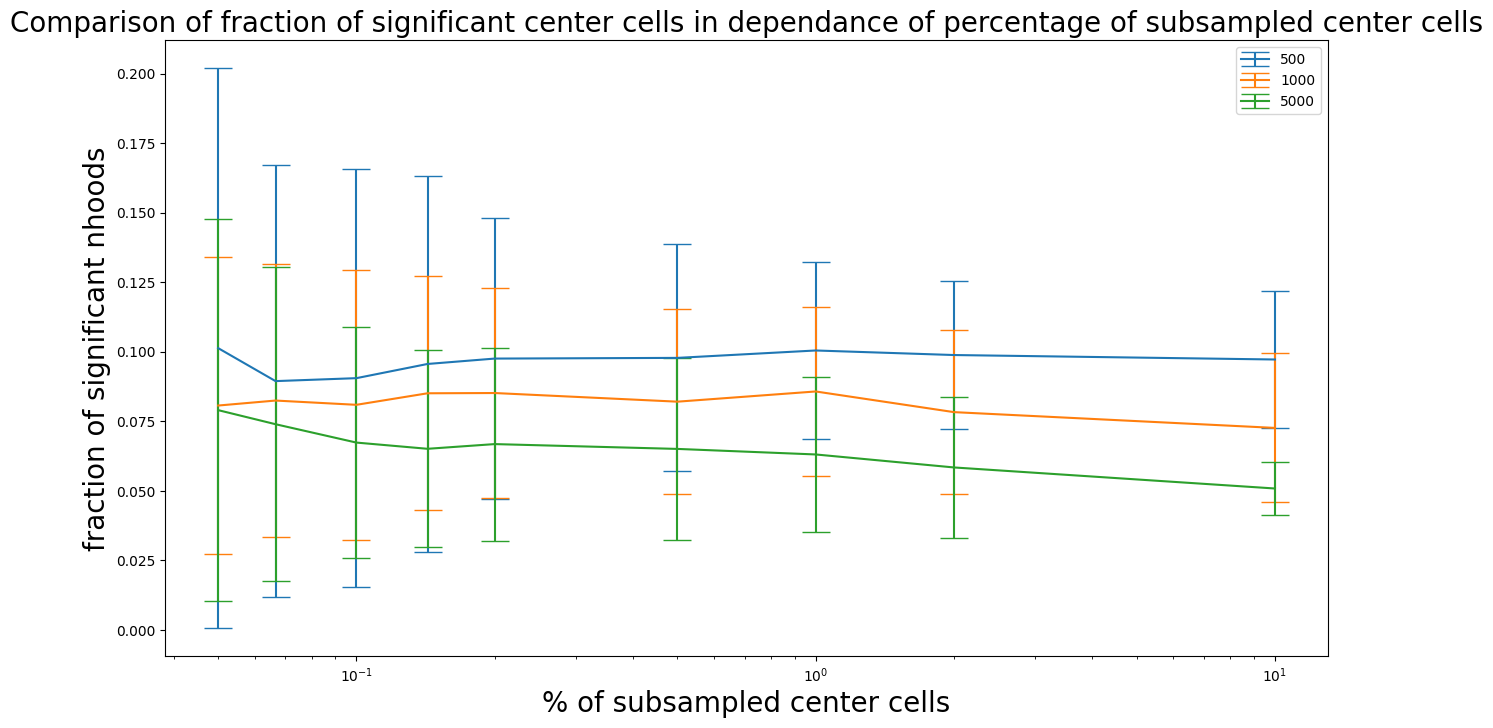

<IPython.core.display.Javascript object>

In [13]:
for k in [500, 1000, 5000]:
    stats = stats_prop[stats_prop.k == k]
    plt.errorbar(
        x=1 / stats.prop, y=stats.fraction, yerr=stats.std_fraction, label=k, capsize=10
    )
plt.legend()
plt.title(
    "Comparison of fraction of significant center cells in dependance of percentage of subsampled center cells",
    fontsize=20,
)
plt.ylabel("fraction of significant nhoods", fontsize=20)
plt.xlabel("% of subsampled center cells", fontsize=20)
plt.legend()

plt.show()

for k in [500, 1000, 5000]:
    stats = stats_prop[stats_prop.k == k]
    plt.errorbar(
        x=(1 / stats.prop) * 100,
        y=stats.fraction,
        yerr=stats.std_fraction,
        label=k,
        capsize=10,
    )
plt.xscale("log")
plt.legend()

plt.title(
    "Comparison of fraction of significant center cells in dependance of percentage of subsampled center cells",
    fontsize=20,
)
plt.ylabel("fraction of significant nhoods", fontsize=20)
plt.xlabel("% of subsampled center cells", fontsize=20)
plt.legend()

The fraction of significant neighborhoods goes down very slightly, but not very significantly with higher numbers of center cells. The choice of center cells is now limited by runtime and graph coverage but is not essential for the outcome. The sandard deviation goes down, as with lower proportions the stocastic component of sampling is more prevalent. 

### Running the method on the whole healthy query + reference: comparing different k's

parameters:
- proportion of cells samples: 1/1000
- runs for standard deviation: 10

### Sheppard 2020

Text(0.5, 0, 'nhood size k')

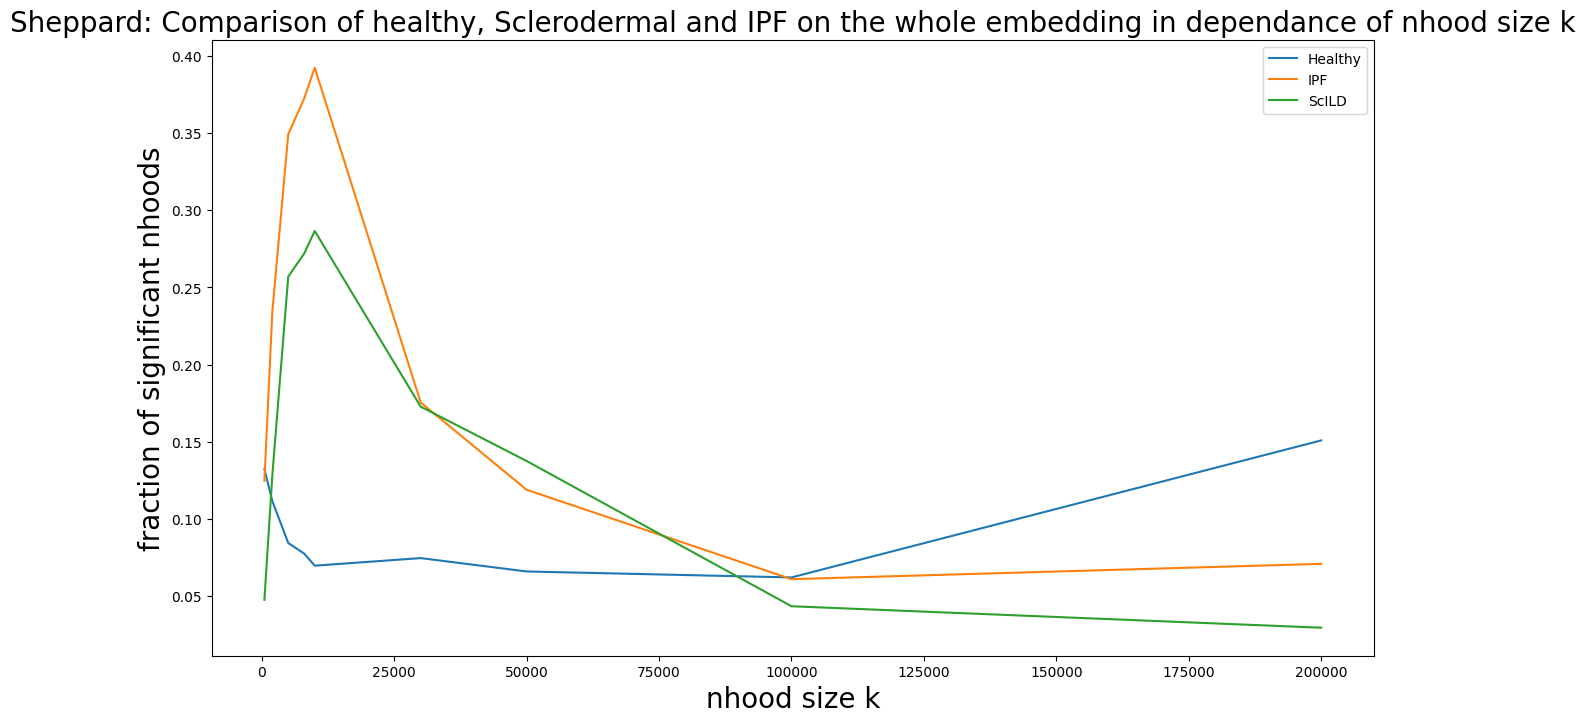

<IPython.core.display.Javascript object>

In [14]:
k_list = [500, 2000, 5000, 8000, 10000, 30000, 50000, 100000, 200000]
prop = 1000
for name, path in [
    ("Healthy", Sheppard_healthy),
    ("IPF", Sheppard_IPF),
    ("ScILD", Sheppard_ScILD),
]:
    stats = load_stats(path, k_list=k_list, prop=prop, runs=10)
    plt.plot(
        stats.k, stats.fraction,label=name,
    )
plt.legend()
plt.title(
    "Sheppard: Comparison of healthy, Sclerodermal and IPF on the whole embedding in dependance of nhood size k",
    fontsize=20,
)
plt.ylabel("fraction of significant nhoods", fontsize=20)
plt.xlabel("nhood size k", fontsize=20)


([<matplotlib.axis.XTick at 0x7ff80677faf0>,
 [Text(500, 0, '500'),
  Text(2000, 0, '2000'),
  Text(5000, 0, '5000'),
  Text(8000, 0, '8000'),
  Text(10000, 0, '10000'),
  Text(30000, 0, '30000'),
  Text(50000, 0, '50000'),
  Text(100000, 0, '100000'),
  Text(200000, 0, '200000')])

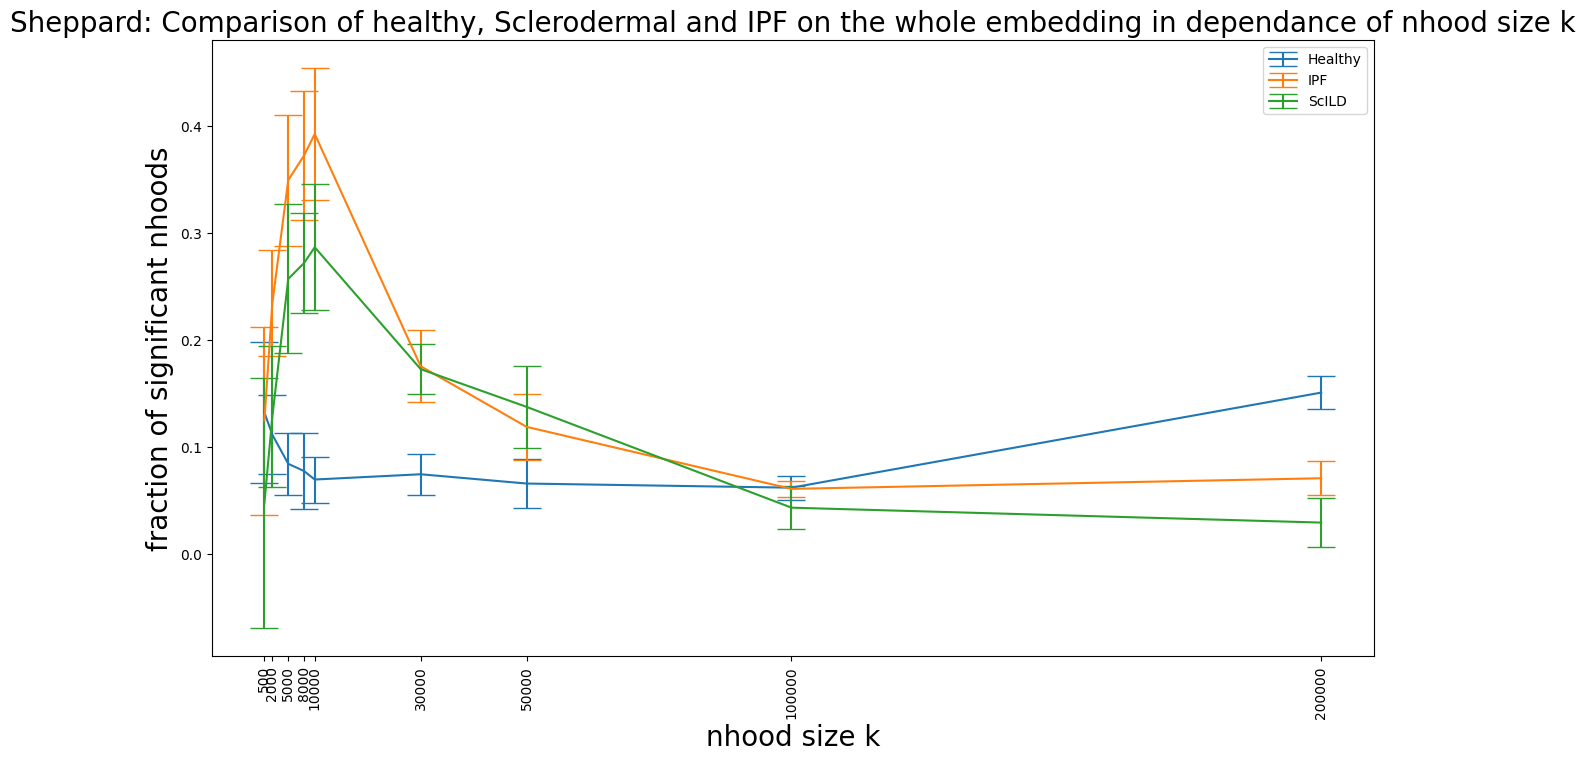

<IPython.core.display.Javascript object>

In [15]:
k_list = [500, 2000, 5000, 8000, 10000, 30000, 50000, 100000, 200000]
prop = 1000
for name, path in [
    ("Healthy", Sheppard_healthy),
    ("IPF", Sheppard_IPF),
    ("ScILD", Sheppard_ScILD),
]:
    stats = load_stats(path, k_list=k_list, prop=prop, runs=10)
    plt.errorbar(
        x=stats.k, y=stats.fraction, yerr=stats.std_fraction, label=name, capsize=10
    )
plt.legend()
plt.title(
    "Sheppard: Comparison of healthy, Sclerodermal and IPF on the whole embedding in dependance of nhood size k",
    fontsize=20,
)
plt.ylabel("fraction of significant nhoods", fontsize=20)
plt.xlabel("nhood size k", fontsize=20)
# plt.xscale("log")
plt.xticks(k_list, rotation=90)

### Schiller 2020

([<matplotlib.axis.XTick at 0x7ff802cc9660>,
 [Text(500, 0, '500'),
  Text(2000, 0, '2000'),
  Text(5000, 0, '5000'),
  Text(8000, 0, '8000'),
  Text(10000, 0, '10000'),
  Text(30000, 0, '30000'),
  Text(50000, 0, '50000'),
  Text(100000, 0, '100000')])

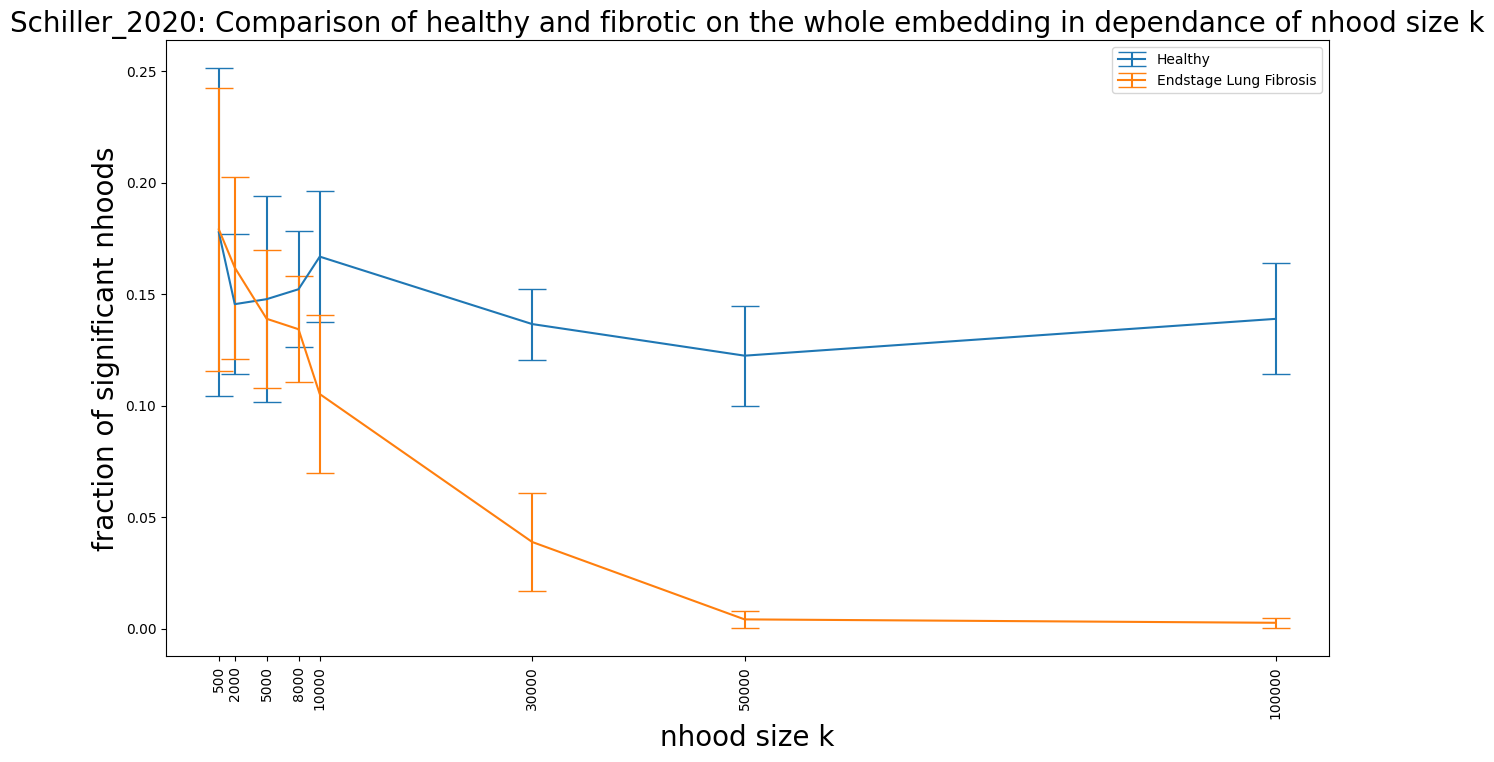

<IPython.core.display.Javascript object>

In [16]:
k_list = [500, 2000, 5000, 8000, 10000, 30000, 50000, 100000]
prop = 1000
for name, path in [
    ("Healthy", Schiller_healthy),
    ("Endstage Lung Fibrosis", Schiller_ELF),
]:
    stats = load_stats(path, k_list=k_list, prop=prop, runs=10)
    plt.errorbar(
        x=stats.k, y=stats.fraction, yerr=stats.std_fraction, label=name, capsize=10
    )
plt.legend()
plt.title(
    "Schiller_2020: Comparison of healthy and fibrotic on the whole embedding in dependance of nhood size k",
    fontsize=20,
)
plt.ylabel("fraction of significant nhoods", fontsize=20)
plt.xlabel("nhood size k", fontsize=20)
# plt.xscale("log")
plt.xticks(k_list, rotation=90)

In [17]:
adata_ext_full = sc.read_h5ad(path_hlca_ext)

<IPython.core.display.Javascript object>

In [18]:
adata_ext_h = adata_ext_full[
    (adata_ext_full.obs.core_or_extension == "core")
    | (adata_ext_full.obs.dataset == "Schiller_2020")
].copy()

<IPython.core.display.Javascript object>

In [19]:
del adata_ext_full

<IPython.core.display.Javascript object>

In [ ]:
sc.pp.neighbors(adata_ext_h, 200)

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
sc.tl.umap(adata_ext_h)

In [ ]:
adata_ext_h.obs["query_health"] = np.nan
adata_ext_h.obs.loc[
    (adata_ext_h.obs.core_or_extension == "extension"), "query_health"
] = "Disease"
adata_ext_h.obs.loc[
    (adata_ext_h.obs.core_or_extension == "extension")
    & (adata_ext_h.obs.lung_condition == "Healthy (tumor adjacent)"),
    "query_health",
] = "Healthy"

In [43]:
h = load_pvalues(Schiller_healthy, 8000, 1000, 5)

<IPython.core.display.Javascript object>

In [44]:
d = load_pvalues(Schiller_ELF, 8000, 1000, 3)

<IPython.core.display.Javascript object>

In [ ]:
adata_ext_h.obs["sampled_significant"] = np.nan

In [ ]:
adata_ext_h.obs.loc[h["Unnamed: 0"], "sampled_significant"] = "Sampled healthy"
adata_ext_h.obs.loc[
    h.loc[h["pvalue_corr"] < 0.05, "Unnamed: 0"], "sampled_significant"
] = "Significant healthy"

In [85]:
adata_ext_h.obs.loc[d["Unnamed: 0"], "sampled_significant"] = "Sampled disease"
adata_ext_h.obs.loc[
    d.loc[d["pvalue_corr"] < 0.05, "Unnamed: 0"], "sampled_significant"
] = "Significant disease"

<IPython.core.display.Javascript object>

/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


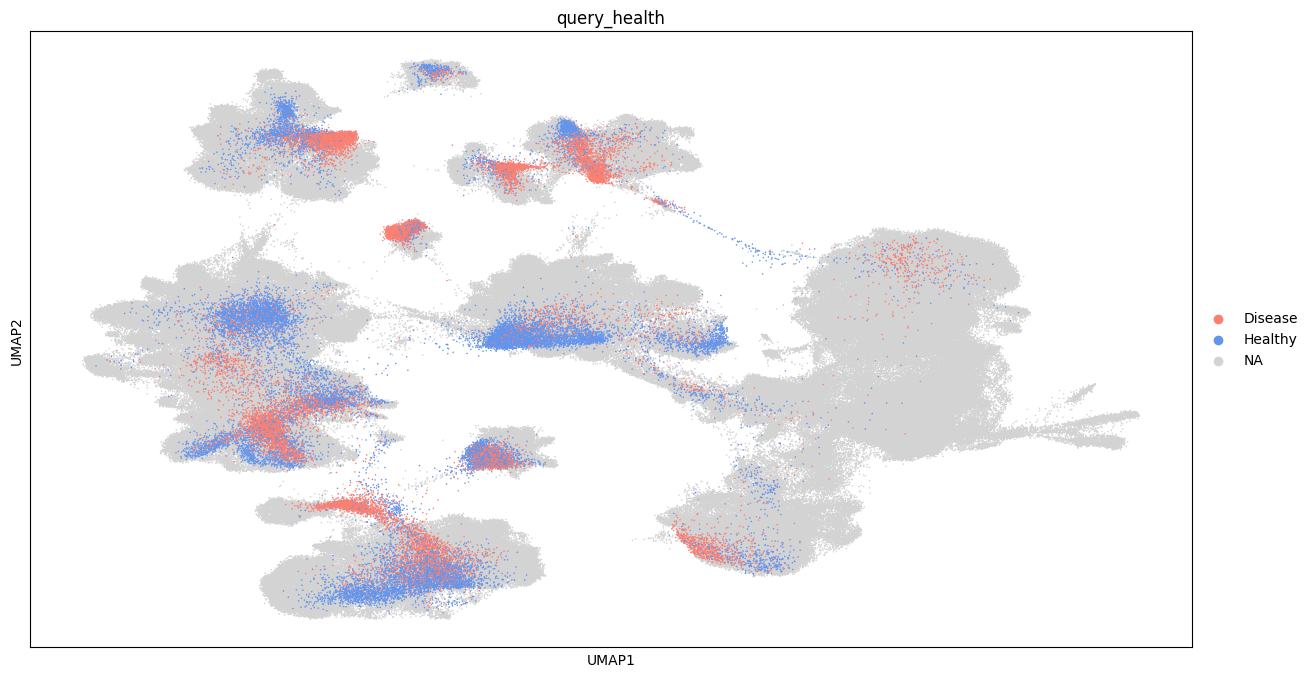

<IPython.core.display.Javascript object>

In [77]:
sc.pl.umap(
    adata_ext_h,
    color="query_health",
    size=5,
    palette={"Disease": "salmon", "Healthy": "cornflowerblue"},
)

/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


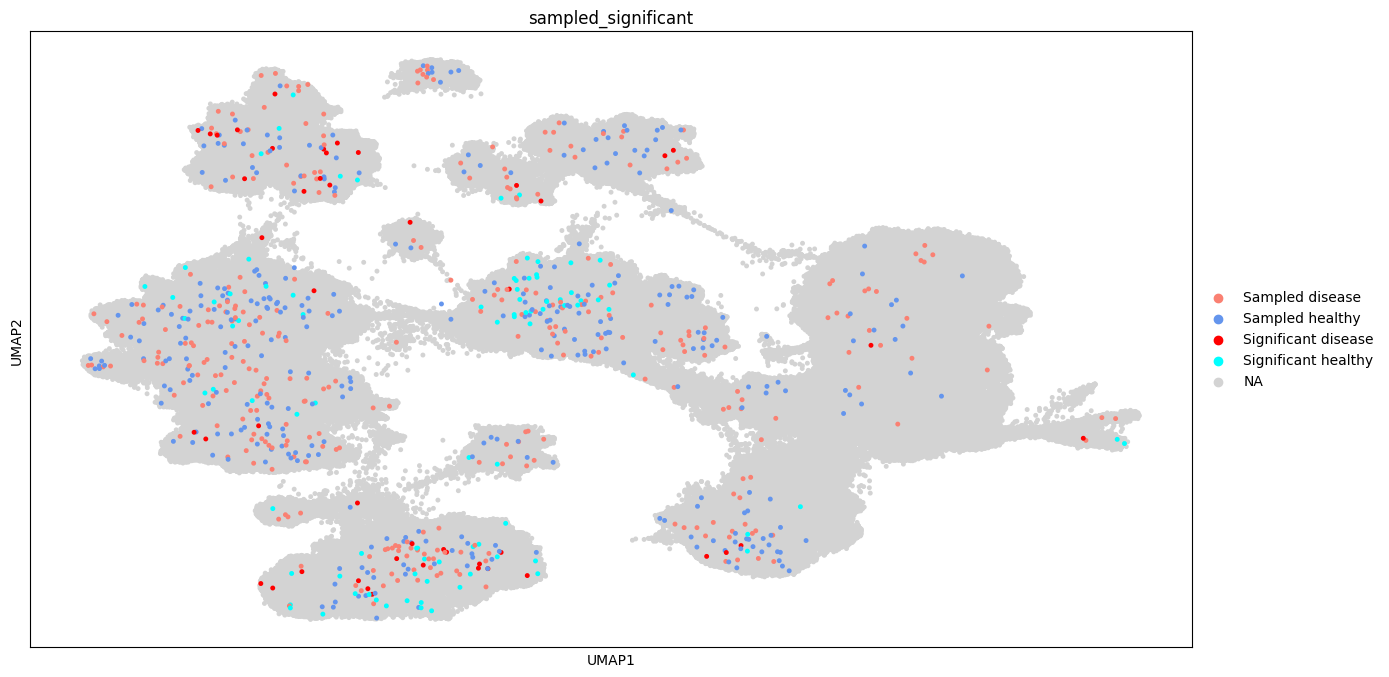

<IPython.core.display.Javascript object>

In [86]:
sc.pl.umap(
    adata_ext_h,
    color="sampled_significant",
    size=50,
    palette={
        "Sampled disease": "salmon",
        "Significant disease": "red",
        "Sampled healthy": "cornflowerblue",
        "Significant healthy": "cyan",
    },
)

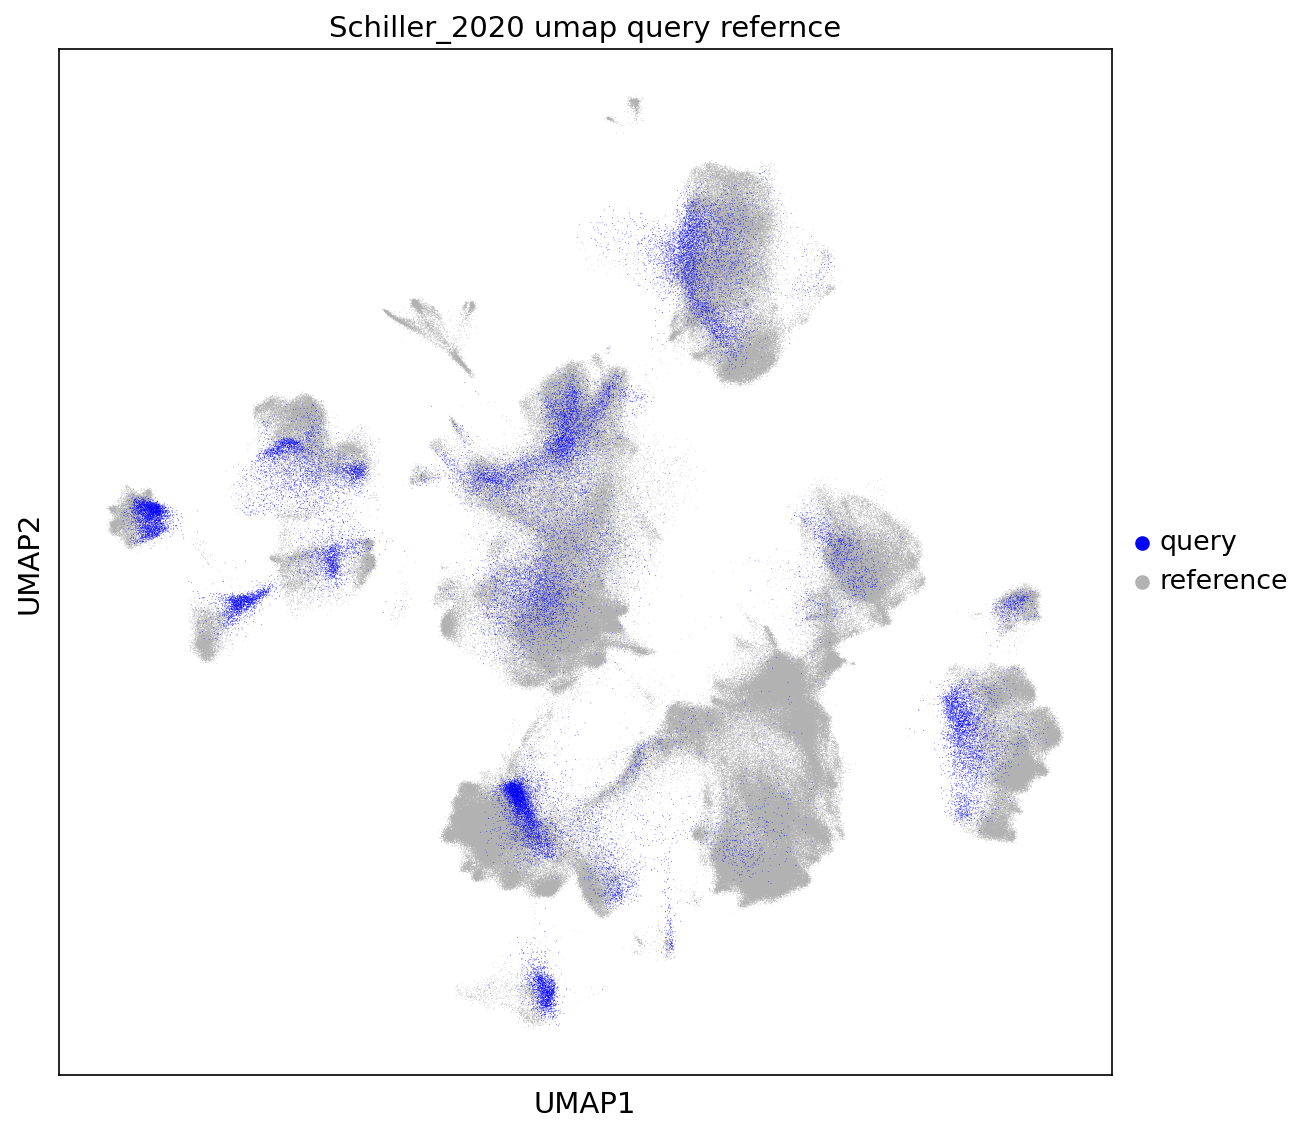

### Schiller pvalue comparison (at n_hood = 10000)

<Axes: xlabel='status', ylabel='-log10(pvalue)'>

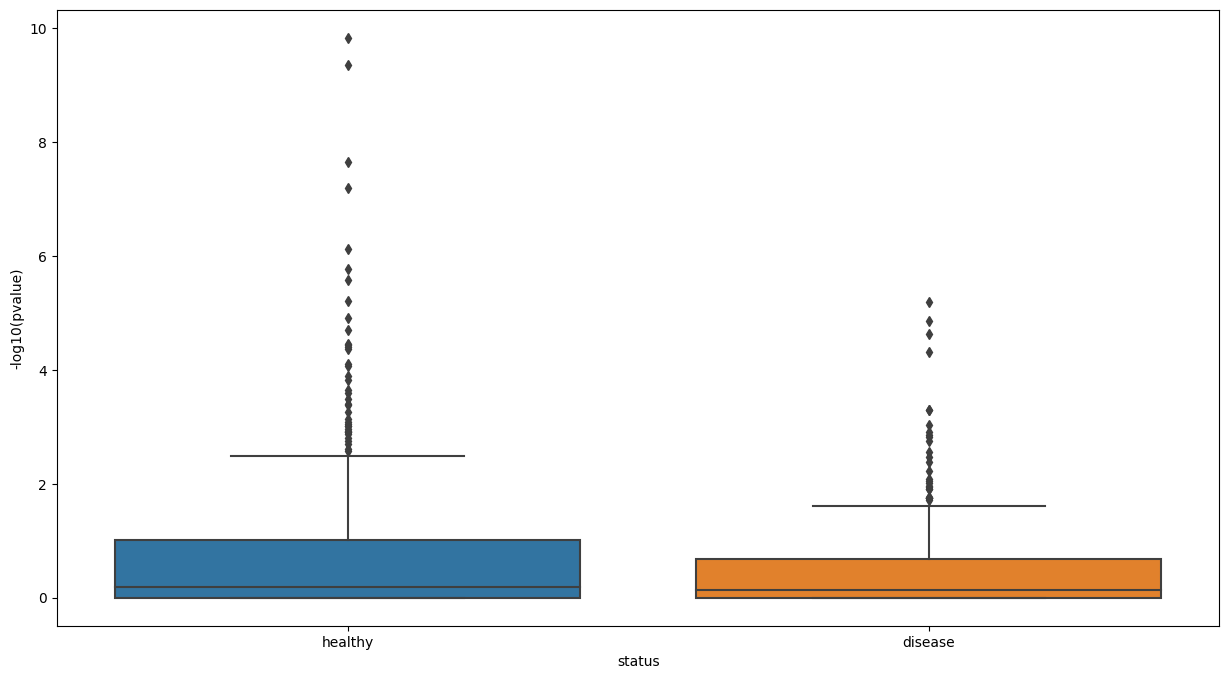

<IPython.core.display.Javascript object>

In [42]:
h["status"] = "healthy"
d["status"] = "disease"
hd = pd.merge(h, d, "outer")
hd["-log10(pvalue)"] = -np.log10(hd["pvalue_corr"])
sns.boxplot(data=hd, x="status", y="-log10(pvalue)")

### Schiller pvalue comparison (at n_hood = 8000)

<Axes: xlabel='status', ylabel='-log10(pvalue)'>

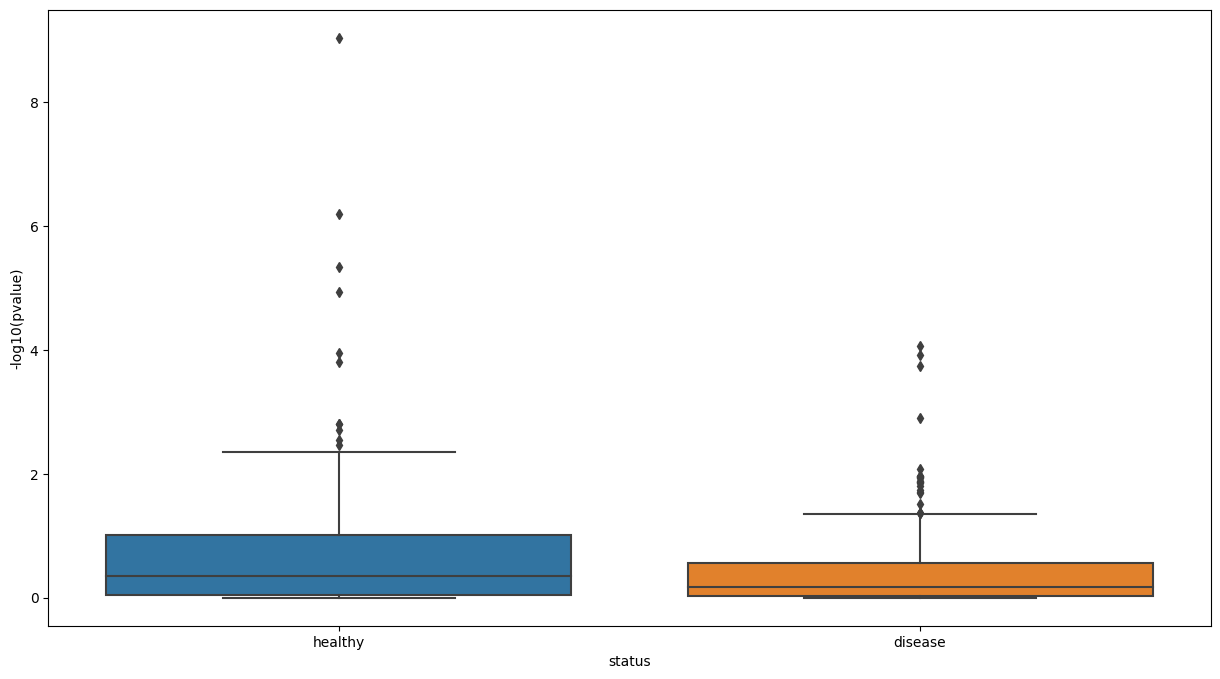

<IPython.core.display.Javascript object>

In [45]:
h["status"] = "healthy"
d["status"] = "disease"
hd = pd.merge(h, d, "outer")
hd["-log10(pvalue)"] = -np.log10(hd["pvalue_corr"])
sns.boxplot(data=hd, x="status", y="-log10(pvalue)")

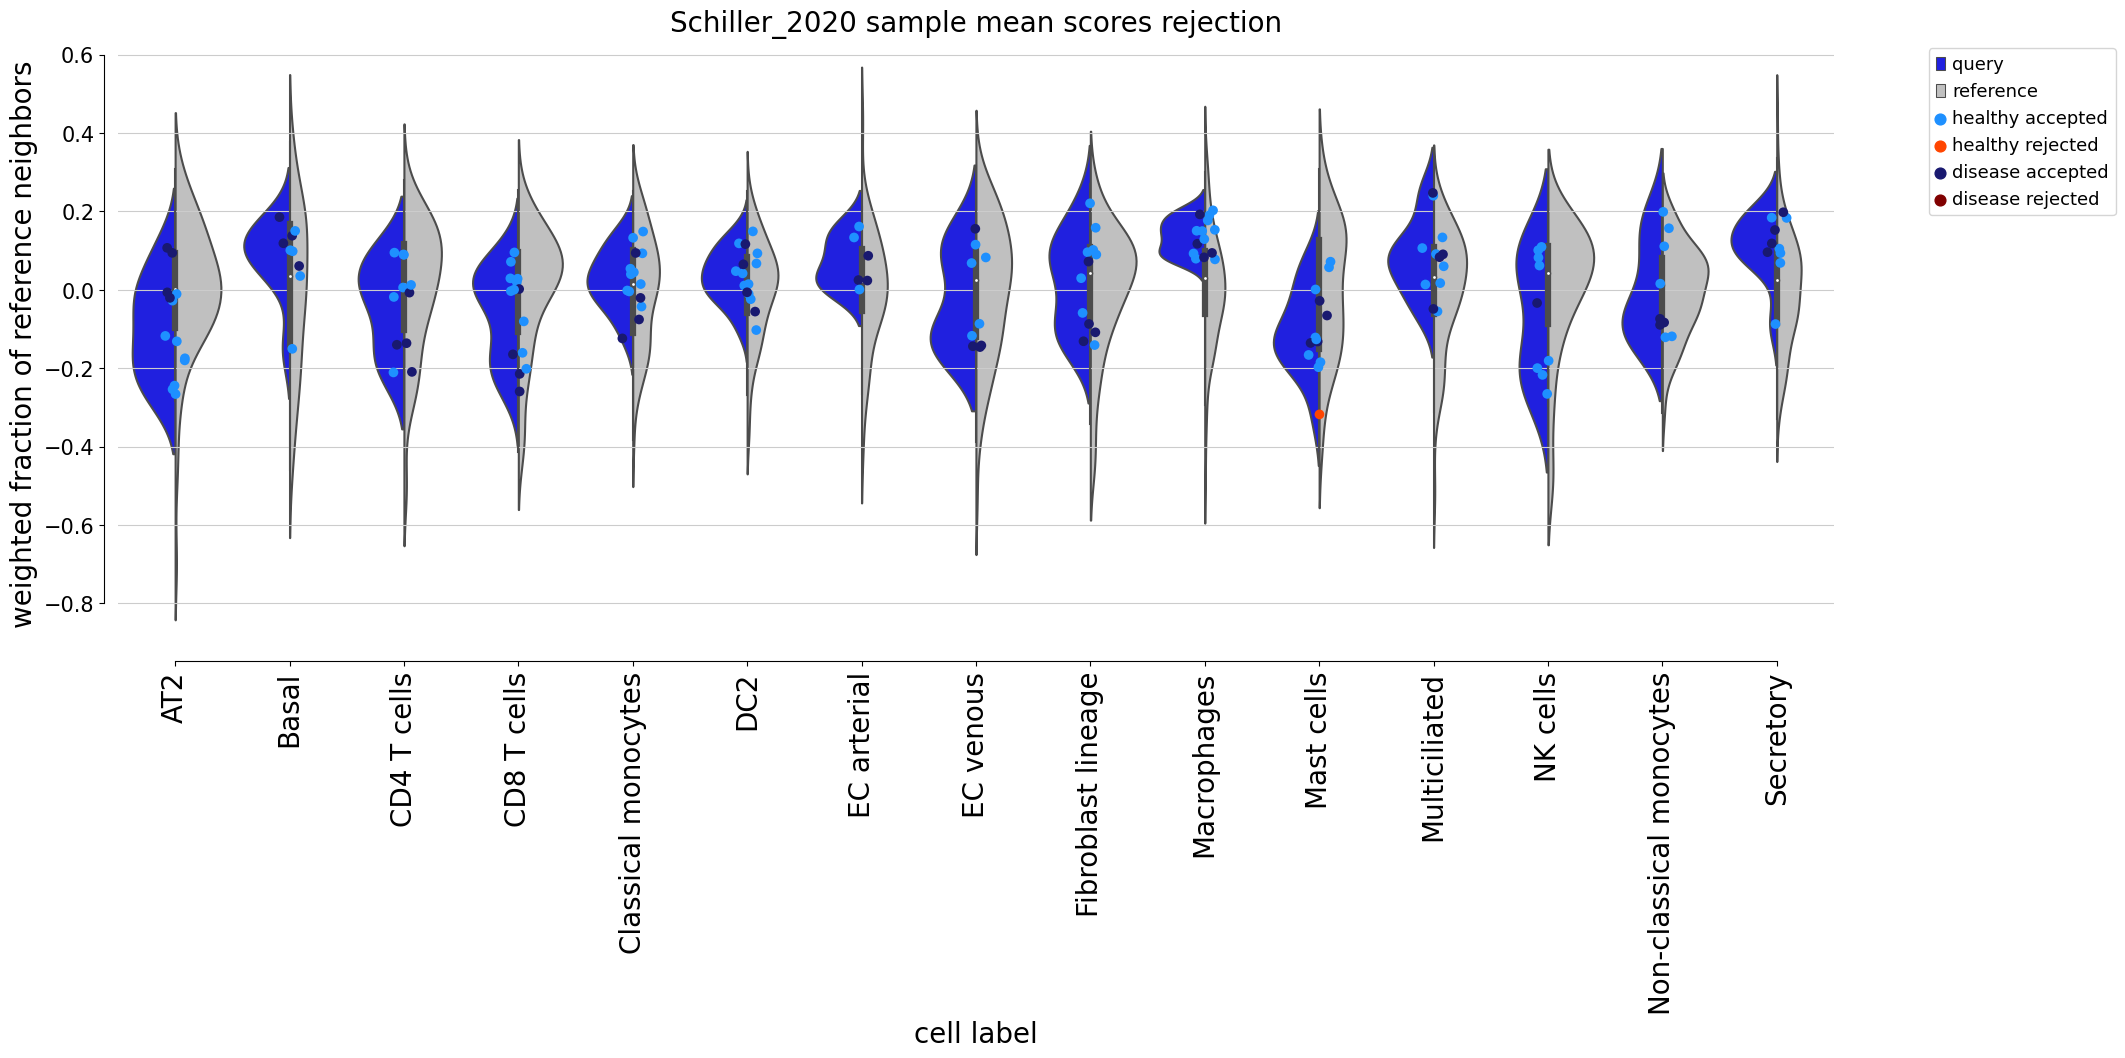

## All datasets full embedding comparison

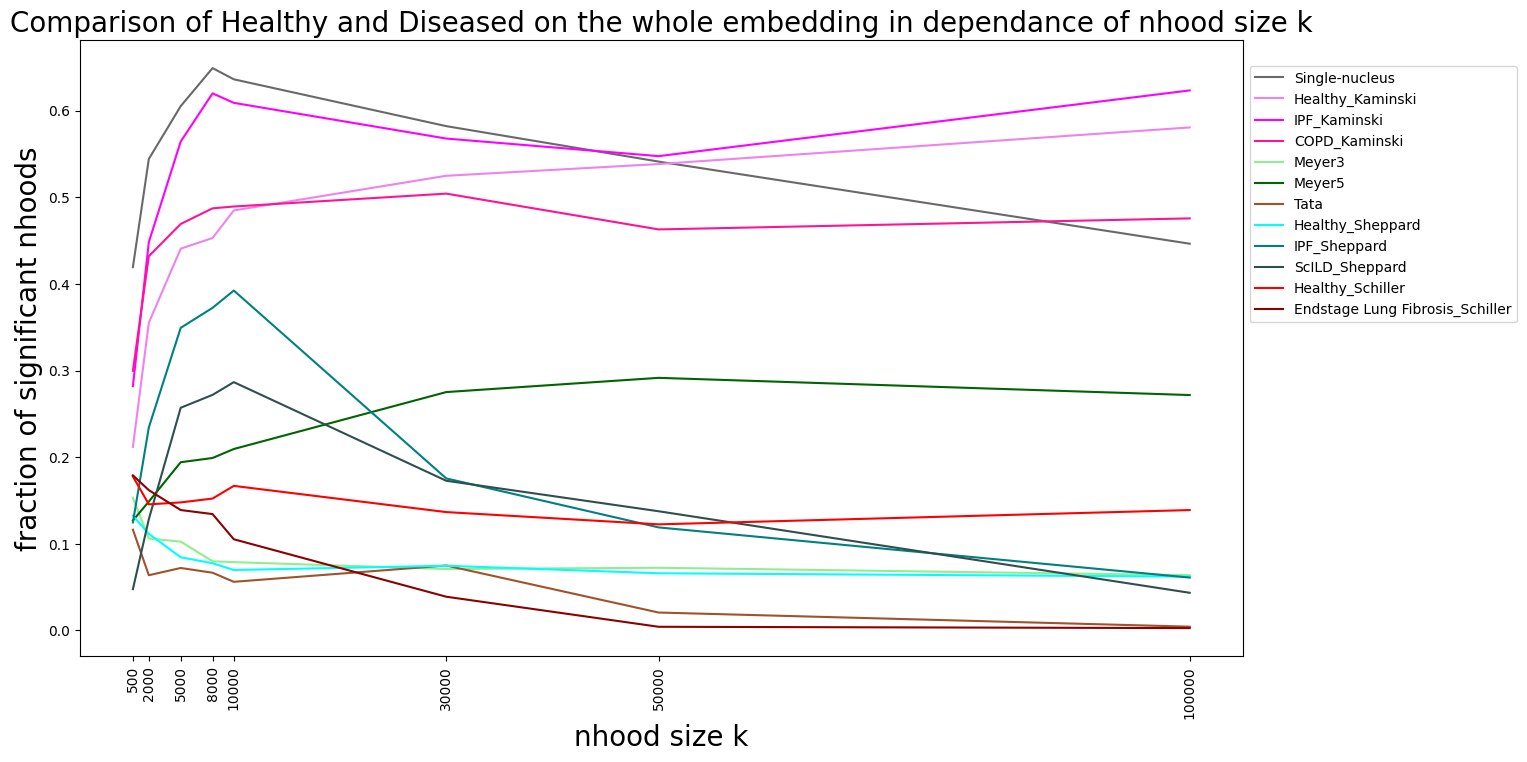

<IPython.core.display.Javascript object>

In [17]:
errorbars = False
k_list = [500, 2000, 5000, 8000, 10000, 30000, 50000, 100000]
prop = 1000
for name, path, color in [
    ("Single-nucleus", Duong, "dimgray"),
    ("Healthy_Kaminski", Kaminski_healthy, "violet"),
    ("IPF_Kaminski", Kaminski_IPF, "magenta"),
    ("COPD_Kaminski", Kaminski_COPD, "deeppink"),
    ("Meyer3", Meyer_3_prime, "lightgreen"),
    ("Meyer5", Meyer_5_prime, "darkgreen"),
    ("Tata", Tata, "sienna"),
    ("Healthy_Sheppard", Sheppard_healthy, "aqua"),
    ("IPF_Sheppard", Sheppard_IPF, "teal"),
    ("ScILD_Sheppard", Sheppard_ScILD, "darkslategray"),
    ("Healthy_Schiller", Schiller_healthy, "red"),
    ("Endstage Lung Fibrosis_Schiller", Schiller_ELF, "darkred"),
]:
    stats = load_stats(path, k_list=k_list, prop=prop, runs=10)
    if errorbars:
        plt.errorbar(
            x=stats.k,
            y=stats.fraction,
            yerr=stats.std_fraction,
            label=name,
            capsize=10,
            color=color,
        )
    else:
        plt.plot(stats.k, stats.fraction, label=name, color=color)
plt.legend(bbox_to_anchor=[1, 0.75], loc="center left")
plt.title(
    "Comparison of Healthy and Diseased on the whole embedding in dependance of nhood size k",
    fontsize=20,
)
plt.ylabel("fraction of significant nhoods", fontsize=20)
plt.xlabel("nhood size k", fontsize=20)
# plt.xscale("log")
plt.xticks(k_list, rotation=90)
# plt.xlim(1000,30000)
plt.show()

# Tryout pvalue aggregation

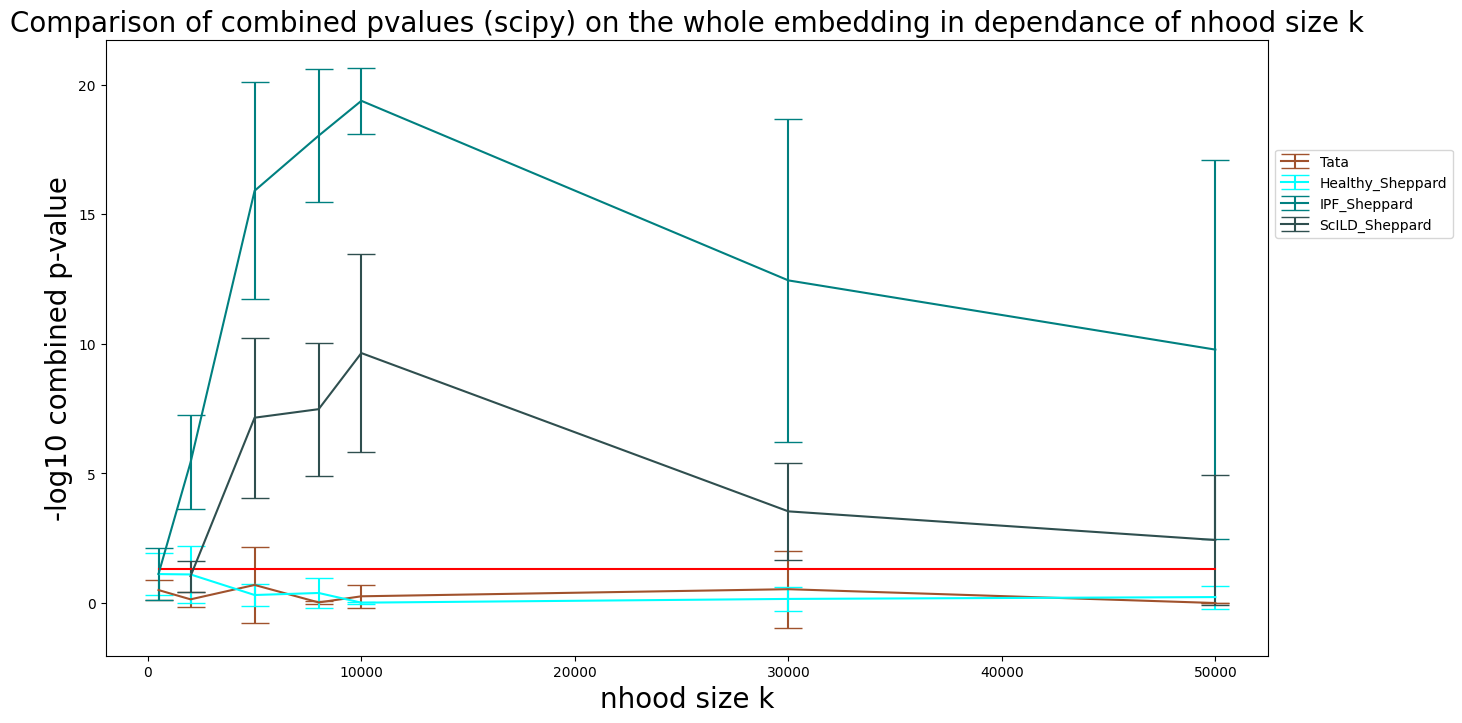

<IPython.core.display.Javascript object>

In [21]:
errorbars = True
k_list = [500, 2000, 5000, 8000, 10000, 30000, 50000]
prop = 1000
for name, path, color in [
    # ("Single-nucleus", Duong, "dimgray"),
    # ("Healthy_Kaminski", Kaminski_healthy, "violet"),
    # ("IPF_Kaminski", Kaminski_IPF, "magenta"),
    # ("COPD_Kaminski", Kaminski_COPD, "deeppink"),
    # ("Meyer3", Meyer_3_prime, "lightgreen"),
    # ("Meyer5", Meyer_5_prime, "darkgreen"),
    ("Tata", Tata, "sienna"),
    ("Healthy_Sheppard", Sheppard_healthy, "aqua"),
    ("IPF_Sheppard", Sheppard_IPF, "teal"),
    ("ScILD_Sheppard", Sheppard_ScILD, "darkslategray"),
    # ("Healthy_Schiller", Schiller_healthy, "red"),
    # ("Endstage Lung Fibrosis_Schiller", Schiller_ELF, "darkred"),
]:
    all_pvalues = []
    for k in k_list:
        pvalues_k = []
        for i in range(0, 10):
            try:
                pvalues = load_pvalues(path, k, 1000, i).pvalue_corr
                pvalue_comb = scipy.stats.combine_pvalues(pvalues)
                if pvalue_comb.pvalue <= 10 ** (-20):
                    pvalues_k.append(-np.log10(10 ** (-20)))
                else:
                    pvalues_k.append(-np.log10(pvalue_comb.pvalue))
            except:
                continue

        all_pvalues.append((k, np.mean(pvalues_k), np.std(pvalues_k)))
    all_pvalues = pd.DataFrame(data=all_pvalues, columns=["k", "mean", "std"])

    if errorbars:
        plt.errorbar(
            x=all_pvalues.k,
            y=all_pvalues["mean"],
            yerr=all_pvalues["std"],
            label=name,
            capsize=10,
            color=color,
        )
    else:
        plt.plot(all_pvalues.k, all_pvalues["mean"], label=name, color=color)


plt.legend(bbox_to_anchor=[1, 0.75], loc="center left")
plt.title(
    "Comparison of combined pvalues (scipy) on the whole embedding in dependance of nhood size k",
    fontsize=20,
)
plt.ylabel("-log10 combined p-value", fontsize=20)
plt.xlabel("nhood size k", fontsize=20)
# plt.xscale("log")
# plt.xticks(k_list, rotation=90)
# plt.xlim(1000,30000)
plt.plot(k_list, [-np.log10(0.05)] * len(k_list), color="red")
plt.show()